<a href="https://colab.research.google.com/github/aliousignate95-SE/credit-scoring-ml/blob/main/scoring_credit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Scoring de crédit : de la régression logistique à LightGBM expliqué par SHAP

**Auteur :** Aliou Signate — Master Économétrie bancaire et financière, expérience en analyse du risque de crédit

## 1. Contexte et objectif

L'objectif est de **prédire le défaut de paiement grave à 2 ans** (`SeriousDlqin2yrs`) de 150 000 emprunteurs, à partir des données Kaggle *Give Me Some Credit*.

Le projet compare trois approches :
- un **scorecard bancaire classique** (régression logistique sur variables WoE) ;
- des **modèles de machine learning** (Random Forest, LightGBM) ;
- puis explique le meilleur modèle avec **SHAP**, pour répondre aux exigences d'explicabilité du secteur bancaire.

**Métriques utilisées :** AUC, Gini (= 2 × AUC − 1) et KS, les standards du scoring crédit.

> Données : télécharger `cs-training.csv` sur Kaggle et l'importer dans Colab.

In [9]:
# Import des librairies et chargement des données
import pandas as pd
import numpy as np


df = pd.read_csv("/cs-training.csv", index_col=0)

## 2. Exploration des données

**Constats :**
- 150 000 clients et 11 colonnes ; **taux de défaut de 6,68 %** : jeu de données déséquilibré, l'accuracy n'est donc pas une métrique pertinente.
- Valeurs manquantes : `MonthlyIncome` (≈ 20 %) et `NumberOfDependents` (≈ 2,6 %).
- Anomalies : âge minimum de 0, codes 96/98 dans les variables de retards, taux d'utilisation des lignes jusqu'à 50 708 et `DebtRatio` extrême lorsque le revenu est manquant.

In [10]:
import pandas as pd

print("Taille :", df.shape)
print("\nValeurs manquantes :")
print(df.isnull().sum())
print("\nTaux de défaut :")
print(df["SeriousDlqin2yrs"].value_counts(normalize=True))
df.describe().T

Taille : (150000, 11)

Valeurs manquantes :
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

Taux de défaut :
SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


## 3. Nettoyage et préparation

1. Suppression des âges impossibles (< 18 ans).
2. Les codes 96/98 des variables de retards sont traités comme valeurs manquantes.
3. Création d'un indicateur `revenu_manquant`.
4. **Découpage train/test (80/20) stratifié AVANT toute imputation.**
5. Plafonnement des valeurs extrêmes au 99e percentile et imputation par la médiane, **calculés sur le train uniquement** puis appliqués au test, pour éviter toute fuite de données.

In [11]:
import numpy as np
from sklearn.model_selection import train_test_split

data = df.copy()

# 1. Supprimer les âges impossibles
data = data[data["age"] >= 18]

# 2. Les codes 96/98 dans les retards deviennent des valeurs manquantes
retards = ["NumberOfTime30-59DaysPastDueNotWorse",
           "NumberOfTimes90DaysLate",
           "NumberOfTime60-89DaysPastDueNotWorse"]
data[retards] = data[retards].replace([96, 98], np.nan)

# 3. Indicateur "revenu manquant" (l'absence d'info est souvent prédictive !)
data["revenu_manquant"] = data["MonthlyIncome"].isnull().astype(int)

# 4. Découpage AVANT toute imputation (pour éviter la fuite de données)
X = data.drop(columns="SeriousDlqin2yrs")
y = data["SeriousDlqin2yrs"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# 5. Plafonner les extrêmes au 99e percentile, calculé sur le TRAIN uniquement
for col in ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio", "MonthlyIncome"]:
    plafond = X_train[col].quantile(0.99)
    X_train[col] = X_train[col].clip(upper=plafond)
    X_test[col] = X_test[col].clip(upper=plafond)

# 6. Imputer les manquants par la médiane du TRAIN
medianes = X_train.median()
X_train = X_train.fillna(medianes)
X_test = X_test.fillna(medianes)

print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Manquants restants :", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())
print("Taux de défaut train/test :", round(y_train.mean(), 4), round(y_test.mean(), 4))

Train : (119999, 11) | Test : (30000, 11)
Manquants restants : 0 0
Taux de défaut train/test : 0.0668 0.0668


## 4. Comparaison des modèles

Trois modèles sont comparés : régression logistique, Random Forest et LightGBM.

**Résultats :**
- LightGBM et Random Forest sont à égalité (Gini ≈ 0,73) et devancent la logistique d'environ 2,4 points de Gini : les arbres capturent les non-linéarités et les interactions.
- L'écart AUC train / AUC test (≈ 0,04) des modèles à arbres indique un sur-apprentissage léger et acceptable.

In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, roc_curve

modeles = {
    "Logistique": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=50,
                                            n_jobs=-1, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=500, learning_rate=0.03,
                               num_leaves=31, random_state=42, verbose=-1),
}

resultats = []
for nom, modele in modeles.items():
    modele.fit(X_train, y_train)
    proba_train = modele.predict_proba(X_train)[:, 1]
    proba_test = modele.predict_proba(X_test)[:, 1]

    auc_train = roc_auc_score(y_train, proba_train)
    auc_test = roc_auc_score(y_test, proba_test)
    fpr, tpr, _ = roc_curve(y_test, proba_test)
    ks = max(tpr - fpr)

    resultats.append({"Modèle": nom,
                      "AUC train": round(auc_train, 4),
                      "AUC test": round(auc_test, 4),
                      "Gini test": round(2 * auc_test - 1, 4),
                      "KS test": round(ks, 4)})
    print(f"{nom} terminé")

pd.DataFrame(resultats)

Logistique terminé
Random Forest terminé
LightGBM terminé


,Modèle,AUC train,AUC test,Gini test,KS test
0,Logistique,0.8489,0.8551,0.7102,0.5501
1,Random Forest,0.9068,0.8668,0.7336,0.5825
2,LightGBM,0.9030,0.8674,0.7347,0.5821


## 5. Scorecard bancaire : WoE et Information Value

Chaque variable est découpée en classes, puis remplacée par son **Weight of Evidence** : WoE = ln(% bons / % mauvais). L'**Information Value** mesure son pouvoir prédictif.

**Constats :**
- **Le comportement prédit mieux que la capacité** : l'utilisation des lignes de crédit (IV = 1,11) et les retards passés dominent, loin devant le revenu (IV = 0,07).
- Les IV supérieurs à 0,5 ont été vérifiés : ce sont des variables comportementales connues au moment de la demande, sans fuite de données.
- Deux variables avec un IV < 0,02 sont écartées.

In [13]:
import numpy as np
import pandas as pd

def calcul_woe(x, y, n_bins=10):
    """Calcule les classes et les WoE d'une variable sur le TRAIN."""
    if x.nunique() <= 20:
        # Variable discrète (nombre de retards, de crédits...) : une classe par valeur
        v = np.sort(x.unique())
        bornes = np.concatenate([[-np.inf], (v[:-1] + v[1:]) / 2, [np.inf]])
    else:
        # Variable continue : découpage en déciles
        bornes = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1)))
        bornes[0], bornes[-1] = -np.inf, np.inf

    classes = pd.cut(x, bins=bornes)
    t = pd.DataFrame({"classe": classes, "y": y}).groupby("classe", observed=True)["y"].agg(["count", "sum"])
    t.columns = ["effectif", "mauvais"]
    t["bons"] = t["effectif"] - t["mauvais"]
    # +0.5 : lissage pour éviter log(0) dans les petites classes
    t["%bons"] = (t["bons"] + 0.5) / t["bons"].sum()
    t["%mauvais"] = (t["mauvais"] + 0.5) / t["mauvais"].sum()
    t["WoE"] = np.log(t["%bons"] / t["%mauvais"])
    t["IV"] = (t["%bons"] - t["%mauvais"]) * t["WoE"]
    return t, bornes

def appliquer_woe(x, t, bornes):
    """Remplace chaque valeur par le WoE de sa classe (bornes du TRAIN)."""
    classes = pd.cut(x, bins=bornes)
    return classes.map(t["WoE"]).astype(float).fillna(0)

# Calcul sur le train, application au train ET au test
tables_woe, X_train_woe, X_test_woe, iv = {}, pd.DataFrame(index=X_train.index), pd.DataFrame(index=X_test.index), {}

for col in X_train.columns:
    t, bornes = calcul_woe(X_train[col], y_train)
    tables_woe[col] = t
    iv[col] = t["IV"].sum()
    X_train_woe[col] = appliquer_woe(X_train[col], t, bornes)
    X_test_woe[col] = appliquer_woe(X_test[col], t, bornes)

# Classement des variables par pouvoir prédictif
iv_table = pd.Series(iv).sort_values(ascending=False).round(4)
print(iv_table)

RevolvingUtilizationOfUnsecuredLines    1.1078
NumberOfTimes90DaysLate                 0.8421
NumberOfTime30-59DaysPastDueNotWorse    0.6956
NumberOfTime60-89DaysPastDueNotWorse    0.5586
age                                     0.2476
DebtRatio                               0.0722
NumberOfOpenCreditLinesAndLoans         0.0684
MonthlyIncome                           0.0661
NumberOfDependents                      0.0360
NumberRealEstateLoansOrLines            0.0135
revenu_manquant                         0.0086
dtype: float64


## 6. Régression logistique sur les WoE

**Résultats :**
- Gini de 0,716 contre 0,710 pour la logistique brute : le WoE réduit l'écart avec LightGBM, sans le combler (1,9 point de Gini), car il ne capte pas les interactions entre variables.
- **Tous les coefficients sont négatifs**, comme attendu : le scorecard est cohérent et défendable devant un comité crédit.
- Aucun sur-apprentissage (AUC train 0,854, AUC test 0,858).

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

# Sélection des variables utiles (IV >= 0.02)
variables = iv_table[iv_table >= 0.02].index.tolist()
print("Variables retenues :", len(variables))

logit_woe = LogisticRegression(max_iter=1000)
logit_woe.fit(X_train_woe[variables], y_train)

proba_train = logit_woe.predict_proba(X_train_woe[variables])[:, 1]
proba_test = logit_woe.predict_proba(X_test_woe[variables])[:, 1]
auc_train = roc_auc_score(y_train, proba_train)
auc_test = roc_auc_score(y_test, proba_test)
fpr, tpr, _ = roc_curve(y_test, proba_test)

resultats.append({"Modèle": "Logistique WoE",
                  "AUC train": round(auc_train, 4),
                  "AUC test": round(auc_test, 4),
                  "Gini test": round(2 * auc_test - 1, 4),
                  "KS test": round(max(tpr - fpr), 4)})
print(pd.DataFrame(resultats))

# Coefficients : avec WoE = ln(%bons/%mauvais), ils doivent TOUS être négatifs
print("\nCoefficients :")
print(pd.Series(logit_woe.coef_[0], index=variables).round(4))

Variables retenues : 9
           Modèle  AUC train  AUC test  Gini test  KS test
0      Logistique     0.8489    0.8551     0.7102   0.5501
1   Random Forest     0.9068    0.8668     0.7336   0.5825
2        LightGBM     0.9030    0.8674     0.7347   0.5821
3  Logistique WoE     0.8537    0.8578     0.7156   0.5662

Coefficients :
RevolvingUtilizationOfUnsecuredLines   -0.6339
NumberOfTimes90DaysLate                -0.5369
NumberOfTime30-59DaysPastDueNotWorse   -0.5399
NumberOfTime60-89DaysPastDueNotWorse   -0.4118
age                                    -0.4308
DebtRatio                              -0.6795
NumberOfOpenCreditLinesAndLoans        -0.2020
MonthlyIncome                          -0.1894
NumberOfDependents                     -0.1667
dtype: float64


## 7. Explicabilité de LightGBM avec SHAP

SHAP décompose chaque prédiction en contributions par variable.

**Vue globale :** l'utilisation des lignes de crédit arrive en tête, comme pour l'IV. Les retards graves pèsent très fort, mais pour une minorité de clients. Le nombre de crédits immobiliers, jugé inutile par l'IV, ressort dans SHAP : l'IV évalue chaque variable seule, SHAP dans le modèle complet.

**Vue individuelle :** le client le plus risqué de l'échantillon (probabilité de défaut de 84,8 %) dépasse sa limite de crédit (110 %) et cumule les retards de paiement. Son profil socio-économique n'est pas alarmant : c'est son comportement de paiement qui explique le score.

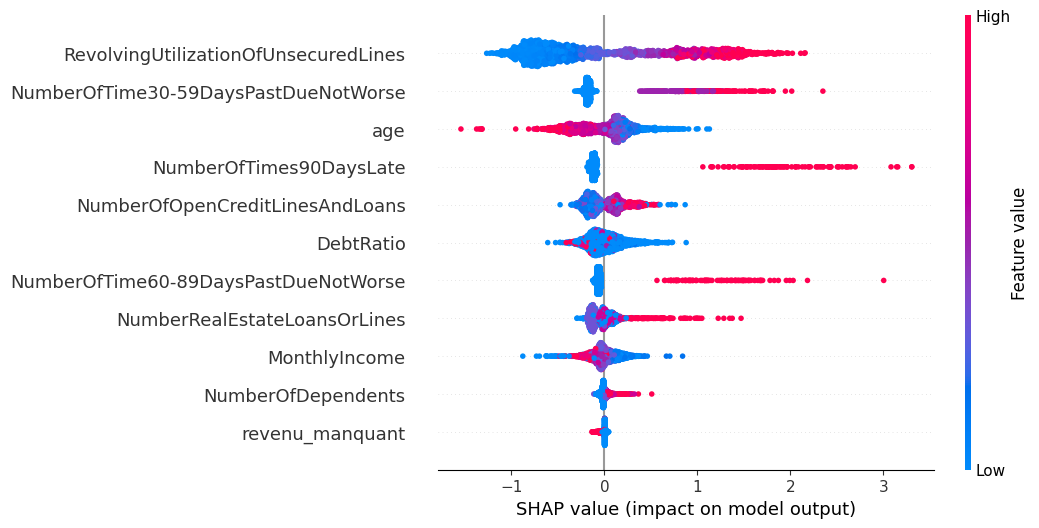

In [15]:
import shap

lgbm = modeles["LightGBM"]

# Échantillon de 2 000 clients du test (pour aller vite)
X_echantillon = X_test.sample(2000, random_state=42)

explainer = shap.TreeExplainer(lgbm)
sv = explainer(X_echantillon)
if len(sv.shape) == 3:      # selon la version de shap
    sv = sv[:, :, 1]

# 1. Vue globale : quelles variables comptent, et dans quel sens ?
shap.plots.beeswarm(sv, max_display=11)

Probabilité de défaut prédite : 84.8%
RevolvingUtilizationOfUnsecuredLines       1.095907
age                                       42.000000
NumberOfTime30-59DaysPastDueNotWorse       3.000000
DebtRatio                                  0.477626
MonthlyIncome                           3083.000000
NumberOfOpenCreditLinesAndLoans            6.000000
NumberOfTimes90DaysLate                    3.000000
NumberRealEstateLoansOrLines               1.000000
NumberOfTime60-89DaysPastDueNotWorse       2.000000
NumberOfDependents                         3.000000
revenu_manquant                            0.000000
Name: 43444, dtype: float64


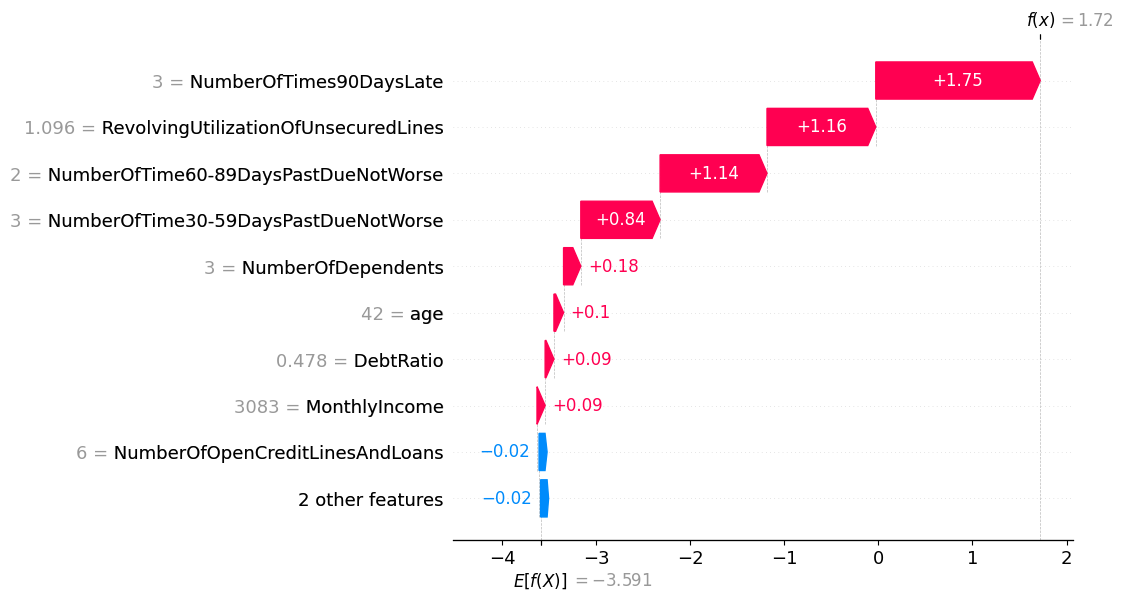

In [16]:
# 2. Vue individuelle : pourquoi CE client est-il jugé très risqué ?
proba = lgbm.predict_proba(X_echantillon)[:, 1]
i = proba.argmax()
print(f"Probabilité de défaut prédite : {proba[i]:.1%}")
print(X_echantillon.iloc[i])
shap.plots.waterfall(sv[i])


## 8. Conclusions

| Modèle | AUC test | Gini test | KS test |
|---|---|---|---|
| Logistique brute | 0,855 | 0,710 | 0,550 |
| Logistique WoE | 0,858 | 0,716 | 0,566 |
| Random Forest | 0,867 | 0,734 | 0,583 |
| **LightGBM** | **0,867** | **0,735** | 0,582 |

- LightGBM offre la meilleure discrimination, et SHAP permet de justifier chaque décision.
- Le scorecard WoE reste une alternative solide, à 1,9 point de Gini, et plus simple à faire valider.

**Pistes d'amélioration :** regroupement des classes WoE (coarse classing), réintégration des crédits immobiliers, choix du seuil d'acceptation selon une matrice de coûts, calibration des probabilités en PD.